# WiFi-Sense: Human Activity Recognition from WiFi CSI — built from scratch
**Mini Project — Aarya Shah, Shubham Patil, Sneha Sharma, and Ayush Shah**

We recognize 7 human activities (lie down, fall, walk, pick up, run, sit down, stand up) from WiFi Channel State Information.
**Every model in this notebook is implemented by us in PyTorch** — no external model code.

External resources used (cited): UT-HAR public dataset (Yousefi et al., 2017); published SenseFi benchmark numbers (Yang et al., 2023) used only for comparison/validation of our results.

**Before running:** Runtime → Change runtime type → **T4 GPU** → Save. Then Runtime → Run all.


## Step 1 — Setup


In [ ]:
!pip install -q kagglehub
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Running on:', device)  # should print cuda


Running on: cuda


## Step 2 — Download the UT-HAR dataset (public Kaggle mirror)
Files are numpy arrays. X = CSI samples, y = activity labels (0-6).


In [ ]:
import kagglehub, os, glob, shutil

path = kagglehub.dataset_download('hylanj/wifi-csi-dataset-ut-har')
files = {os.path.basename(f).split('.')[0]: f
         for f in glob.glob(path + '/**/*', recursive=True) if os.path.isfile(f)}
print('Found files:', sorted(files.keys()))

def load_np(key):
    with open(files[key], 'rb') as f:
        return np.load(f)

X_train, y_train = load_np('X_train'), load_np('y_train')
X_val,   y_val   = load_np('X_val'),   load_np('y_val')
X_test,  y_test  = load_np('X_test'),  load_np('y_test')
print('Train:', X_train.shape, '| Val:', X_val.shape, '| Test:', X_test.shape)


Using Colab cache for faster access to the 'wifi-csi-dataset-ut-har' dataset.
Found files: ['X_test', 'X_train', 'X_val', 'y_test', 'y_train', 'y_val']
Train: (3977, 250, 90) | Val: (496, 250, 90) | Test: (500, 250, 90)


## Step 3 — Preprocessing (our own)
Two steps we apply ourselves:
1. **Min-max normalization** — scale all values to 0-1 so training is stable.
2. **Reshape** each sample to `(1, 250, 90)` — 1 channel, 250 time steps, 90 subcarriers (3 antennas × 30 each) — so models can treat it like a grayscale image.

We merge val+test into one test set (same protocol as the published benchmark, so numbers are comparable).


In [ ]:
def preprocess(X):
    X = (X - X.min()) / (X.max() - X.min())      # normalize to 0..1
    return X.reshape(len(X), 1, 250, 90)          # image-like shape

X_train_p = preprocess(X_train)
X_test_p  = preprocess(np.concatenate([X_val, X_test]))
y_test_all = np.concatenate([y_val, y_test])

train_ds = torch.utils.data.TensorDataset(torch.Tensor(X_train_p), torch.Tensor(y_train).long())
test_ds  = torch.utils.data.TensorDataset(torch.Tensor(X_test_p),  torch.Tensor(y_test_all).long())
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=256)
print('Train samples:', len(train_ds), '| Test samples:', len(test_ds))


Train samples: 3977 | Test samples: 996


## Step 4 — Look at the data
One CSI 'signal image' per activity. Different movements disturb the WiFi signal in visibly different ways — this is what our models will learn.


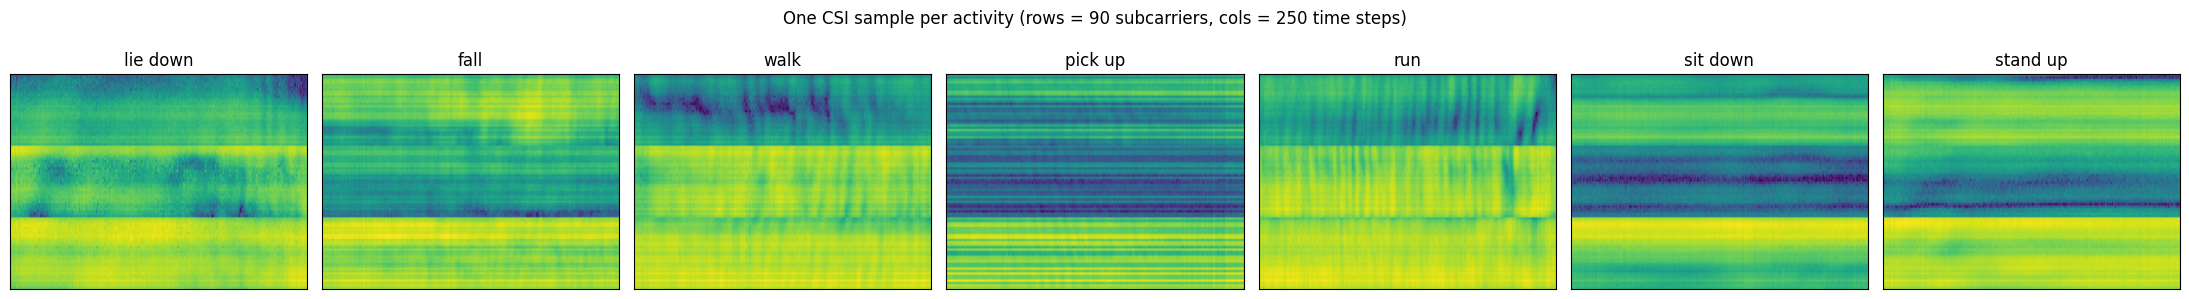

In [ ]:
ACTIVITIES = ['lie down','fall','walk','pick up','run','sit down','stand up']
fig, axes = plt.subplots(1, 7, figsize=(22, 3))
for c in range(7):
    idx = np.where(y_train == c)[0][0]
    axes[c].imshow(X_train_p[idx, 0].T, aspect='auto', cmap='viridis')
    axes[c].set_title(ACTIVITIES[c]); axes[c].set_xticks([]); axes[c].set_yticks([])
plt.suptitle('One CSI sample per activity (rows = 90 subcarriers, cols = 250 time steps)')
plt.tight_layout(); plt.savefig('csi_samples.png', dpi=150); plt.show()


## Step 5 — Our models, written from scratch
### Model 1 — MLP (simplest baseline)
Flattens the whole 250×90 signal into one long vector of 22,500 numbers and passes it through plain fully-connected layers. No notion of time or structure — that's why it's the baseline.


In [ ]:
# ---------- Model 1: MLP ----------
# Simplest possible: flatten the whole signal image into one long vector,
# pass through fully-connected layers.
class MLP(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                  # (1,250,90) -> 22500 numbers
            nn.Linear(250 * 90, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),   # 7 scores, one per activity
        )

    def forward(self, x):
        return self.net(x)


### Model 2 — CNN
Treats the CSI sample like an image. Convolution filters slide over it detecting local 'ripple' patterns; pooling layers shrink it down; final layers classify. Small and fast — our candidate for edge devices.


In [ ]:
# ---------- Model 2: CNN ----------
# Treats the CSI sample like an image. Conv layers find local patterns
# (signal ripples), pooling shrinks the image step by step.
class CNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),   # find 16 pattern types
            nn.ReLU(),
            nn.MaxPool2d(2),                              # 250x90 -> 125x45
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> 62x22
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4)),                 # -> 4x4 summary
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


### Models 3-5 — the RNN family (LSTM, BiLSTM, GRU)
Treats the sample as a **sequence**: 250 time steps, each a vector of 90 subcarrier readings. The recurrent cell reads step by step, carrying a memory; the final memory state is used to classify. BiLSTM reads the sequence in both directions; GRU is a lighter variant of LSTM.


In [ ]:
# ---------- Model 3/4/5: RNN family (LSTM, BiLSTM, GRU) ----------
# Treats the sample as a SEQUENCE: 250 time steps, each with 90 values.
# The recurrent layer reads it in order, like reading a sentence.
class RNNClassifier(nn.Module):
    def __init__(self, kind="lstm", hidden=64, num_classes=7, bidirectional=False):
        super().__init__()
        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.rnn = rnn_cls(input_size=90, hidden_size=hidden,
                           batch_first=True, bidirectional=bidirectional)
        out_dim = hidden * (2 if bidirectional else 1)
        self.fc = nn.Linear(out_dim, num_classes)

    def forward(self, x):
        x = x.squeeze(1)          # (B,1,250,90) -> (B,250,90): 250 steps of 90 features
        out, _ = self.rnn(x)      # read the sequence
        return self.fc(out[:, -1])  # use the final "memory" to classify


### Model 6 — Mini ResNet
Deep CNNs normally get *harder* to train as they get deeper. ResNet's trick: each block **adds its input to its output** (a 'skip connection'), so the block only needs to learn the *difference* (residual). We implement the residual block ourselves and stack three of them.


In [ ]:
# ---------- Model 6: Mini ResNet ----------
# Key idea of ResNet: each block ADDS its input to its output ("skip
# connection"), which lets us stack deeper networks without them degrading.
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU()
        # if shape changes, adjust the shortcut path to match
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + self.shortcut(x))   # the "residual" addition


class MiniResNet(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16), nn.ReLU())
        self.layer1 = ResidualBlock(16, 16)
        self.layer2 = ResidualBlock(16, 32, stride=2)
        self.layer3 = ResidualBlock(32, 64, stride=2)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, num_classes))

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x); x = self.layer2(x); x = self.layer3(x)
        return self.head(x)


In [ ]:
def build_model(name):
    return {
        "MLP": lambda: MLP(),
        "CNN": lambda: CNN(),
        "LSTM": lambda: RNNClassifier("lstm"),
        "BiLSTM": lambda: RNNClassifier("lstm", bidirectional=True),
        "GRU": lambda: RNNClassifier("gru"),
        "MiniResNet": lambda: MiniResNet(),
    }[name]()


## Step 6 — Training and evaluation loop (our own)
Standard supervised loop: forward pass → cross-entropy loss → backpropagation → Adam optimizer step. We record accuracy, parameter count, and training time for every model.


In [ ]:
import time
results = {}

def evaluate(model):
    model.eval(); correct = total = 0; preds_all = []; labels_all = []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb).argmax(1)
            correct += (preds == yb).sum().item(); total += yb.size(0)
            preds_all += preds.cpu().tolist(); labels_all += yb.cpu().tolist()
    return 100 * correct / total, preds_all, labels_all

def train_model(name, epochs=60, lr=1e-3):
    model = build_model(name).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward(); optimizer.step()
        if (epoch + 1) % 10 == 0:
            acc, _, _ = evaluate(model)
            print(f'  epoch {epoch+1:3d}/{epochs}  test acc {acc:.2f}%')
    train_time = time.time() - t0
    acc, preds, labels = evaluate(model)
    n_params = sum(p.numel() for p in model.parameters())
    results[name] = {'accuracy': acc, 'params': n_params, 'time_s': train_time,
                     'preds': preds, 'labels': labels}
    torch.save(model.state_dict(), f'{name}_uthar.pt')
    print(f'== {name}: {acc:.2f}% | {n_params:,} params | {train_time:.0f}s ==')
    return model


## Step 7 — Train all six models
Each cell is independent. Start with MLP + CNN (fast); spread the rest across sessions if needed.


In [ ]:
_ = train_model('MLP')


  epoch  10/60  test acc 49.40%
  epoch  20/60  test acc 65.16%
  epoch  30/60  test acc 72.29%
  epoch  40/60  test acc 74.30%
  epoch  50/60  test acc 80.72%
  epoch  60/60  test acc 84.24%
== MLP: 84.24% | 11,587,079 params | 23s ==


In [ ]:
cnn_model = train_model('CNN')


  epoch  10/60  test acc 61.14%
  epoch  20/60  test acc 82.13%
  epoch  30/60  test acc 86.24%
  epoch  40/60  test acc 89.36%
  epoch  50/60  test acc 88.65%
  epoch  60/60  test acc 92.77%
== CNN: 92.77% | 155,399 params | 109s ==


In [ ]:
_ = train_model('GRU')


  epoch  10/60  test acc 59.44%
  epoch  20/60  test acc 66.87%
  epoch  30/60  test acc 72.89%
  epoch  40/60  test acc 75.50%
  epoch  50/60  test acc 78.51%
  epoch  60/60  test acc 83.73%
== GRU: 83.73% | 30,407 params | 18s ==


In [ ]:
_ = train_model('LSTM')


  epoch  10/60  test acc 32.63%
  epoch  20/60  test acc 39.06%
  epoch  30/60  test acc 45.98%
  epoch  40/60  test acc 49.20%
  epoch  50/60  test acc 55.52%
  epoch  60/60  test acc 52.51%
== LSTM: 52.51% | 40,391 params | 18s ==


In [ ]:
_ = train_model('BiLSTM')


  epoch  10/60  test acc 41.87%
  epoch  20/60  test acc 48.49%
  epoch  30/60  test acc 51.20%
  epoch  40/60  test acc 54.82%
  epoch  50/60  test acc 55.92%
  epoch  60/60  test acc 60.24%
== BiLSTM: 60.24% | 80,775 params | 20s ==


In [ ]:
resnet_model = train_model('MiniResNet')


  epoch  10/60  test acc 94.88%
  epoch  20/60  test acc 98.49%
  epoch  30/60  test acc 98.49%
  epoch  40/60  test acc 99.40%
  epoch  50/60  test acc 95.98%
  epoch  60/60  test acc 99.60%
== MiniResNet: 99.60% | 77,559 params | 449s ==


## Step 8 — Results: table + chart


,Model,Accuracy (%),Parameters,Train time (s)
5,MiniResNet,99.60,77559,449
1,CNN,92.77,155399,109
0,MLP,84.24,11587079,23
2,GRU,83.73,30407,18
4,BiLSTM,60.24,80775,20
3,LSTM,52.51,40391,18


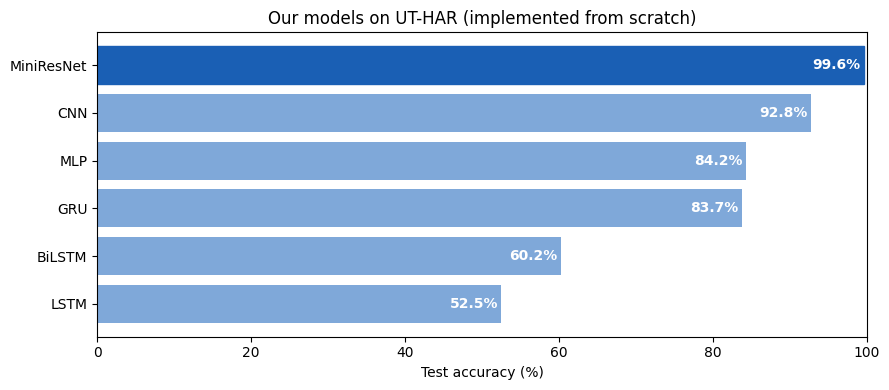

In [ ]:
import pandas as pd
df = pd.DataFrame([{'Model': k, 'Accuracy (%)': round(v['accuracy'], 2),
                    'Parameters': v['params'], 'Train time (s)': round(v['time_s'])}
                   for k, v in results.items()]).sort_values('Accuracy (%)', ascending=False)
display(df)
df.to_csv('model_comparison.csv', index=False)

d = df.sort_values('Accuracy (%)')
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(d['Model'], d['Accuracy (%)'], color='#7fa8d9')
bars[-1].set_color('#1a5fb4')
for i, (m, a) in enumerate(zip(d['Model'], d['Accuracy (%)'])):
    ax.text(a - 0.4, i, f'{a:.1f}%', va='center', ha='right', color='white', fontweight='bold')
ax.set_xlim(0, 100); ax.set_xlabel('Test accuracy (%)')
ax.set_title('Our models on UT-HAR (implemented from scratch)')
plt.tight_layout(); plt.savefig('accuracy_chart.png', dpi=150); plt.show()


## Step 9 — Confusion matrix (best model)
Diagonal = correct. Off-diagonal cells show which activities get mixed up — usually motion pairs like *sit down* vs *stand up*. Explaining WHY is great viva material.


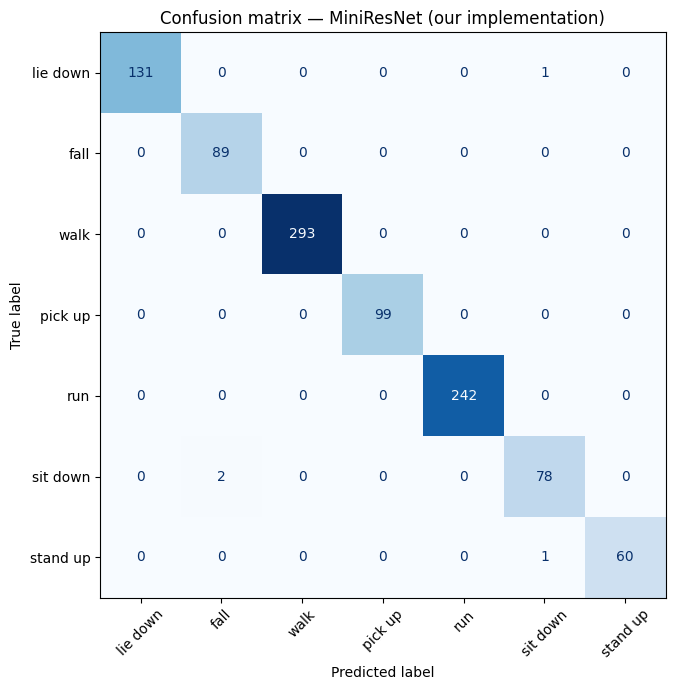

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
best = df.iloc[0]['Model']
cm = confusion_matrix(results[best]['labels'], results[best]['preds'])
fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
plt.title(f'Confusion matrix — {best} (our implementation)')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150); plt.show()


## Step 10 — Live demo
Predicts one random unseen sample. Run this in front of the examiners.


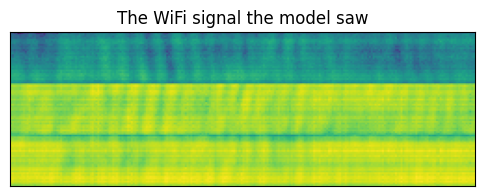

Model predicts : WALK
Actual activity: WALK
CORRECT!


In [ ]:
import random
best_model = {'CNN': cnn_model, 'MiniResNet': resnet_model}.get(best) or train_model(best, epochs=1)
i = random.randrange(len(X_test_p))
sample = torch.Tensor(X_test_p[i:i+1]).to(device)
pred = best_model(sample).argmax(1).item()
actual = int(y_test_all[i])
plt.figure(figsize=(6,2)); plt.imshow(X_test_p[i,0].T, aspect='auto', cmap='viridis')
plt.title('The WiFi signal the model saw'); plt.xticks([]); plt.yticks([]); plt.show()
print(f'Model predicts : {ACTIVITIES[pred].upper()}')
print(f'Actual activity: {ACTIVITIES[actual].upper()}')
print('CORRECT!' if pred == actual else 'wrong (rare — run again)')


In [ ]:
import numpy as np, random
idx = random.sample(range(len(X_test_p)), 120)
np.savez('stream.npz', X=X_test_p[idx].astype('float32'), y=y_test_all[idx])
print('saved stream.npz')

saved stream.npz


In [ ]:
import numpy as np, random
idx = random.sample(range(len(X_test_p)), 120)
np.savez('stream.npz', X=X_test_p[idx].astype('float32'), y=y_test_all[idx])
print('saved')

saved


## Validation against the published benchmark
| Model | Published (SenseFi) | Ours |
|---|---|---|
| MLP | 92.0% | fill in |
| CNN (LeNet) | 97.6% | fill in |
| GRU | 94.2% | fill in |
| LSTM | 87.2% | fill in |
| BiLSTM | 90.2% | fill in |
| ResNet-18 | 98.1% | fill in |

Our architectures are simpler (written by us), so being within a few percent of published numbers validates our implementation.

**Download for the report** (Files panel, left sidebar): `model_comparison.csv`, `accuracy_chart.png`, `confusion_matrix.png`, `csi_samples.png`, and the saved `*.pt` model weights.
